In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import pandas as pd
import numpy as np
from google.colab import files
from IPython.display import display

# Upload your CSV file
uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Load the raw dataset
df_raw = pd.read_csv(filename)

# Create a working copy
df = df_raw.copy(deep=True)

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())


Saving Nassau Candy Distributor.csv to Nassau Candy Distributor.csv
Dataset loaded successfully
Rows: 10194
Columns: 18


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [3]:

# Inspect data types and non-null counts
df.info()

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Count", ascending=False
    )
)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

,Missing_Count,Missing_Percentage
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Country/Region,0,0.0
City,0,0.0
State/Province,0,0.0
Postal Code,0,0.0


In [4]:

date_columns = ["Order Date", "Ship Date"]

for col in date_columns:
    print(f"\n{col}")
    print("Original dtype:", df[col].dtype)
    print("Sample values:")
    display(df[col].dropna().head(10))
    print("Minimum raw value:", df[col].min())
    print("Maximum raw value:", df[col].max())



Order Date
Original dtype: object
Sample values:


,Order Date
0,03-01-2024
1,04-01-2024
2,04-01-2024
3,04-01-2024
4,05-01-2024
5,06-01-2024
6,06-01-2024
7,06-01-2024
8,06-01-2024
9,06-01-2024


Minimum raw value: 01-01-2025
Maximum raw value: 31-12-2025

Ship Date
Original dtype: object
Sample values:


,Ship Date
0,30-06-2026
1,01-07-2026
2,01-07-2026
3,01-07-2026
4,05-07-2026
5,03-07-2026
6,03-07-2026
7,30-06-2026
8,03-07-2026
9,03-07-2026


Minimum raw value: 01-01-2027
Maximum raw value: 31-12-2029


In [5]:

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        dayfirst=True
    )

print(df[date_columns].dtypes)

display(df[date_columns].head())


Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


,Order Date,Ship Date
0,2024-01-03,2026-06-30
1,2024-01-04,2026-07-01
2,2024-01-04,2026-07-01
3,2024-01-04,2026-07-01
4,2024-01-05,2026-07-05


In [6]:

date_quality = pd.DataFrame({
    "Minimum": df[date_columns].min(),
    "Maximum": df[date_columns].max(),
    "Missing_After_Parsing": df[date_columns].isna().sum()
})

display(date_quality)

# Show records whose dates failed to parse
invalid_dates = df[
    df[date_columns].isna().any(axis=1)
]

print("Records with missing or invalid dates:",
      len(invalid_dates))

display(invalid_dates.head(10))


,Minimum,Maximum,Missing_After_Parsing
Order Date,2024-01-02,2025-12-31,0
Ship Date,2026-06-30,2030-06-28,0


Records with missing or invalid dates: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost


In [7]:

df["Lead Time (Days)"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("Lead-time summary:")
display(df["Lead Time (Days)"].describe())

# Negative lead times
negative_lead = df[
    df["Lead Time (Days)"] < 0
]

# Zero-day lead times
zero_lead = df[
    df["Lead Time (Days)"] == 0
]

# Lead times greater than 365 days
long_lead = df[
    df["Lead Time (Days)"] > 365
]

print("Negative lead times:", len(negative_lead))
print("Zero-day lead times:", len(zero_lead))
print("Lead times > 365 days:", len(long_lead))

display(
    long_lead[
        ["Order ID", "Order Date", "Ship Date",
         "Lead Time (Days)", "Ship Mode"]
    ].head(10)
)


Lead-time summary:


,Lead Time (Days)
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000


Negative lead times: 0
Zero-day lead times: 0
Lead times > 365 days: 10194


,Order ID,Order Date,Ship Date,Lead Time (Days),Ship Mode
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,909,Standard Class
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,909,Standard Class
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,909,Standard Class
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,909,Standard Class
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,912,Standard Class
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03,909,Standard Class
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03,909,Standard Class
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30,906,First Class
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03,909,Standard Class
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03,909,Standard Class


In [8]:

df_dates = pd.read_csv(filename, dtype=str)

for col in date_columns:
    df_dates[col] = df_dates[col].str.strip()

def compare_date_parse(dayfirst):
    parsed_order = pd.to_datetime(
        df_dates["Order Date"],
        errors="coerce",
        dayfirst=dayfirst
    )

    parsed_ship = pd.to_datetime(
        df_dates["Ship Date"],
        errors="coerce",
        dayfirst=dayfirst
    )

    lead = (parsed_ship - parsed_order).dt.days

    return {
        "Interpretation": (
            "Day-first" if dayfirst else "Month-first"
        ),
        "Unparseable_Order_Dates": parsed_order.isna().sum(),
        "Unparseable_Ship_Dates": parsed_ship.isna().sum(),
        "Negative_Lead_Times": (lead < 0).sum(),
        "Zero_Lead_Times": (lead == 0).sum(),
        "Over_365_Days": (lead > 365).sum(),
        "Median_Lead_Time": lead.median(),
        "Minimum_Lead_Time": lead.min(),
        "Maximum_Lead_Time": lead.max()
    }

comparison = pd.DataFrame([
    compare_date_parse(True),
    compare_date_parse(False)
])

display(comparison)


/tmp/ipykernel_2169/3129532577.py:13: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  parsed_ship = pd.to_datetime(


,Interpretation,Unparseable_Order_Dates,Unparseable_Ship_Dates,Negative_Lead_Times,Zero_Lead_Times,Over_365_Days,Median_Lead_Time,Minimum_Lead_Time,Maximum_Lead_Time
0,Day-first,0,0,0,0,10194,1274.0,904.0,1642.0
1,Month-first,6064,0,0,0,4130,1361.0,613.0,1965.0


In [9]:

# Exact duplicate rows
print("Exact duplicate rows:",
      df.duplicated().sum())

# Duplicate Row IDs
print("Duplicate Row IDs:",
      df["Row ID"].duplicated().sum())

# Number of unique orders
print("Unique orders:",
      df["Order ID"].nunique())

# Orders appearing in more than one row
order_counts = df["Order ID"].value_counts()

print("Orders with multiple rows:",
      (order_counts > 1).sum())

display(
    order_counts[order_counts > 1].head(10)
)


Exact duplicate rows: 0
Duplicate Row IDs: 0
Unique orders: 8549
Orders with multiple rows: 1373


,count
Order ID,
US-2022-130974-CHO-SCR-58000,5
US-2024-104731-CHO-FUD-51000,5
US-2024-100111-CHO-NUT-13000,5
US-2022-112130-CHO-FUD-51000,5
US-2024-113278-CHO-MIL-31000,5
US-2024-157987-CHO-NUT-13000,5
US-2022-126977-CHO-SCR-58000,5
US-2021-155502-CHO-MIL-31000,5
US-2024-109253-CHO-SCR-58000,4


In [10]:

shipment_quality = pd.DataFrame({
    "Missing_Order_Date": df["Order Date"].isna(),
    "Missing_Ship_Date": df["Ship Date"].isna(),
    "Missing_Ship_Mode": df["Ship Mode"].isna(),
    "Missing_State": df["State/Province"].isna(),
    "Missing_Region": df["Region"].isna()
}).sum().to_frame("Count")

display(shipment_quality)

# Records that cannot have a calculated lead time
missing_shipment_date = df[
    df["Order Date"].isna() |
    df["Ship Date"].isna()
]

print("Records missing an order or ship date:",
      len(missing_shipment_date))

display(missing_shipment_date.head(10))


,Count
Missing_Order_Date,0
Missing_Ship_Date,0
Missing_Ship_Mode,0
Missing_State,0
Missing_Region,0


Records missing an order or ship date: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Lead Time (Days)


In [11]:

shipment_quality = pd.DataFrame({
    "Missing_Order_Date": df["Order Date"].isna(),
    "Missing_Ship_Date": df["Ship Date"].isna(),
    "Missing_Ship_Mode": df["Ship Mode"].isna(),
    "Missing_State": df["State/Province"].isna(),
    "Missing_Region": df["Region"].isna()
}).sum().to_frame("Count")

display(shipment_quality)

# Records that cannot have a calculated lead time
missing_shipment_date = df[
    df["Order Date"].isna() |
    df["Ship Date"].isna()
]

print("Records missing an order or ship date:",
      len(missing_shipment_date))

display(missing_shipment_date.head(10))


,Count
Missing_Order_Date,0
Missing_Ship_Date,0
Missing_Ship_Mode,0
Missing_State,0
Missing_Region,0


Records missing an order or ship date: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Lead Time (Days)


In [12]:

geo_columns = [
    "Country/Region",
    "City",
    "State/Province",
    "Region"
]

for col in geo_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
    )

# Standardize capitalization where appropriate
for col in ["Country/Region", "City", "Region"]:
    df[col] = df[col].str.title()

df["State/Province"] = df["State/Province"].str.title()

# Inspect distinct values after standardization
for col in geo_columns:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique().tolist())[:30])



Country/Region:
['Canada', 'United States']

City:
['Aberdeen', 'Abilene', 'Akron', 'Albuquerque', 'Alexandria', 'Allen', 'Allentown', 'Altoona', 'Amarillo', 'Anaheim', 'Andover', 'Ann Arbor', 'Antioch', 'Apopka', 'Apple Valley', 'Appleton', 'Arlington', 'Arlington Heights', 'Arvada', 'Asheville', 'Athens', 'Atlanta', 'Atlantic City', 'Auburn', 'Aurora', 'Austin', 'Avondale', 'Bakersfield', 'Baltimore', 'Bangor']

State/Province:
['Alabama', 'Alberta', 'Arizona', 'Arkansas', 'British Columbia', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District Of Columbia', 'Florida', 'Georgia', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Manitoba', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada']

Region:
['Atlantic', 'Gulf', 'Interior', 'Pacific']


In [13]:

df["Postal Code"] = (
    df["Postal Code"]
    .astype("string")
    .str.strip()
)

print(df["Postal Code"].dtype)


string


In [14]:

audit = {
    "Rows in raw data": len(df_raw),
    "Rows in working data": len(df),
    "Exact duplicate rows": int(df.duplicated().sum()),
    "Duplicate Row IDs": int(df["Row ID"].duplicated().sum()),
    "Missing order dates": int(df["Order Date"].isna().sum()),
    "Missing ship dates": int(df["Ship Date"].isna().sum()),
    "Negative lead times": int((df["Lead Time (Days)"] < 0).sum()),
    "Zero-day lead times": int((df["Lead Time (Days)"] == 0).sum()),
    "Lead times > 365 days": int((df["Lead Time (Days)"] > 365).sum())
}

audit_report = pd.DataFrame(
    list(audit.items()),
    columns=["Data Quality Check", "Count"]
)

display(audit_report)


,Data Quality Check,Count
0,Rows in raw data,10194
1,Rows in working data,10194
2,Exact duplicate rows,0
3,Duplicate Row IDs,0
4,Missing order dates,0
5,Missing ship dates,0
6,Negative lead times,0
7,Zero-day lead times,0
8,Lead times > 365 days,10194


In [15]:

# Preserve every record in the working dataset.
df_clean = df.copy()

# Define records eligible for provisional lead-time analysis.
valid_dates = (
    df_clean["Order Date"].notna() &
    df_clean["Ship Date"].notna()
)

valid_chronology = (
    df_clean["Lead Time (Days)"] >= 0
)

# Provisional screening threshold for investigation.
within_review_threshold = (
    df_clean["Lead Time (Days)"] <= 365
)

lead_time_eligible = (
    valid_dates &
    valid_chronology &
    within_review_threshold
)

df_leadtime = df_clean.loc[
    lead_time_eligible
].copy()

print("Raw records:", len(df_raw))
print("Working records:", len(df_clean))
print("Eligible for provisional lead-time analysis:",
      len(df_leadtime))
print("Excluded from provisional lead-time analysis:",
      len(df_clean) - len(df_leadtime))


Raw records: 10194
Working records: 10194
Eligible for provisional lead-time analysis: 0
Excluded from provisional lead-time analysis: 10194


In [16]:

# Export the cleaned working dataset
df_clean.to_csv(
    "Nassau_Candy_Cleaned.csv",
    index=False
)

# Export provisional lead-time dataset
df_leadtime.to_csv(
    "Nassau_Candy_LeadTime_Eligible.csv",
    index=False
)

# Export data-quality report
audit_report.to_csv(
    "Nassau_Candy_Data_Quality_Report.csv",
    index=False
)

print("Export completed.")


Export completed.


In [17]:

# Reload the original CSV as text to preserve source values
raw_dates = pd.read_csv(filename, dtype=str)

print("First 10 original date pairs:")
display(raw_dates[
    ["Order Date", "Ship Date"]
].head(10))

# Parse using an explicit day-month-year format
order_dates = pd.to_datetime(
    raw_dates["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

ship_dates = pd.to_datetime(
    raw_dates["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Summarize the parsed date ranges
print("Order date range:",
      order_dates.min(), "to", order_dates.max())

print("Ship date range:",
      ship_dates.min(), "to", ship_dates.max())

# Check whether all dates parsed successfully
print("Invalid order dates:", order_dates.isna().sum())
print("Invalid ship dates:", ship_dates.isna().sum())

# Calculate differences without modifying the source
lead_time = (ship_dates - order_dates).dt.days

print("\nLead-time distribution:")
display(lead_time.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
))

# Show the first and last records by lead time
investigation = raw_dates[
    ["Order ID", "Order Date", "Ship Date"]
].copy()

investigation["Lead Time (Days)"] = lead_time

print("Shortest lead times:")
display(investigation.nsmallest(
    10, "Lead Time (Days)"
))

print("Longest lead times:")
display(investigation.nlargest(
    10, "Lead Time (Days)"
))


First 10 original date pairs:


,Order Date,Ship Date
0,03-01-2024,30-06-2026
1,04-01-2024,01-07-2026
2,04-01-2024,01-07-2026
3,04-01-2024,01-07-2026
4,05-01-2024,05-07-2026
5,06-01-2024,03-07-2026
6,06-01-2024,03-07-2026
7,06-01-2024,30-06-2026
8,06-01-2024,03-07-2026
9,06-01-2024,03-07-2026


Order date range: 2024-01-02 00:00:00 to 2025-12-31 00:00:00
Ship date range: 2026-06-30 00:00:00 to 2030-06-28 00:00:00
Invalid order dates: 0
Invalid ship dates: 0

Lead-time distribution:


,0
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
10%,908.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
90%,1640.000000
max,1642.000000


Shortest lead times:


,Order ID,Order Date,Ship Date,Lead Time (Days)
154,US-2021-116239-CHO-FUD-51000,04-03-2024,25-08-2026,904
203,US-2021-158442-CHO-MIL-31000,17-03-2024,07-09-2026,904
211,US-2021-158442-CHO-FUD-51000,17-03-2024,07-09-2026,904
212,US-2021-158442-CHO-TRI-54000,17-03-2024,07-09-2026,904
247,US-2021-129609-CHO-TRI-54000,22-03-2024,12-09-2026,904
280,US-2021-130428-CHO-FUD-51000,31-03-2024,21-09-2026,904
282,US-2021-130428-CHO-TRI-54000,31-03-2024,21-09-2026,904
284,US-2021-130428-CHO-FUD-51000,31-03-2024,21-09-2026,904
286,US-2021-112403-CHO-NUT-13000,31-03-2024,21-09-2026,904
338,US-2021-165806-CHO-MIL-31000,07-04-2024,28-09-2026,904


Longest lead times:


,Order ID,Order Date,Ship Date,Lead Time (Days)
7063,US-2024-136007-CHO-SCR-58000,23-02-2025,23-08-2029,1642
7065,US-2024-136007-CHO-TRI-54000,23-02-2025,23-08-2029,1642
7094,US-2024-111815-CHO-SCR-58000,03-03-2025,31-08-2029,1642
7100,US-2024-111815-CHO-TRI-54000,03-03-2025,31-08-2029,1642
7130,US-2024-104080-CHO-NUT-13000,08-03-2025,05-09-2029,1642
7131,US-2024-104080-CHO-TRI-54000,08-03-2025,05-09-2029,1642
7167,US-2024-105851-CHO-NUT-13000,13-03-2025,10-09-2029,1642
7276,US-2024-113208-CHO-TRI-54000,26-03-2025,23-09-2029,1642
7279,US-2024-162033-CHO-TRI-54000,26-03-2025,23-09-2029,1642
7283,US-2024-162033-CHO-MIL-31000,26-03-2025,23-09-2029,1642


In [18]:

# Check the relationship between order and shipping dates

check_df = raw_dates.copy()

check_df["Order Date Parsed"] = pd.to_datetime(
    check_df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

check_df["Ship Date Parsed"] = pd.to_datetime(
    check_df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

check_df["Lead Time"] = (
    check_df["Ship Date Parsed"] -
    check_df["Order Date Parsed"]
).dt.days

print("Order year counts:")
display(check_df["Order Date Parsed"].dt.year.value_counts().sort_index())

print("\nShip year counts:")
display(check_df["Ship Date Parsed"].dt.year.value_counts().sort_index())

print("\nLead-time frequency:")
display(check_df["Lead Time"].value_counts().sort_index().head(20))

print("\nSample records with dates:")
display(
    check_df[
        ["Order ID", "Order Date", "Ship Date", "Lead Time"]
    ].sample(15, random_state=42)
)


Order year counts:


,count
Order Date Parsed,
2024,4181
2025,6013



Ship year counts:


,count
Ship Date Parsed,
2026,711
2027,2089
2028,2367
2029,2899
2030,2128



Lead-time frequency:


,count
Lead Time,
904,89
905,40
906,289
907,176
908,591
909,519
910,207
911,134
912,4



Sample records with dates:


,Order ID,Order Date,Ship Date,Lead Time
6636,US-2023-108777-CHO-FUD-51000,12-12-2025,03-06-2029,1269
3742,US-2022-102778-CHO-TRI-54000,21-11-2024,16-05-2028,1272
5114,US-2023-153577-CHO-TRI-54000,27-06-2025,21-12-2028,1273
6505,US-2023-161025-CHO-FUD-51000,03-12-2025,31-05-2029,1275
10072,US-2024-155376-CHO-SCR-58000,22-12-2025,19-06-2030,1640
6520,US-2023-114489-CHO-FUD-51000,05-12-2025,31-05-2029,1273
3149,US-2022-165057-CHO-FUD-51000,11-09-2024,07-03-2028,1273
2876,US-2022-120810-CHO-SCR-58000,23-07-2024,17-01-2028,1273
5610,US-2023-151372-CHO-NUT-13000,05-09-2025,26-02-2029,1270
7742,US-2024-132297-CHO-FUD-51000,27-05-2025,23-11-2029,1641


In [19]:

# Display the most common order-date and ship-date combinations

date_pairs = (
    check_df.groupby(
        ["Order Date", "Ship Date", "Lead Time"],
        dropna=False
    )
    .size()
    .reset_index(name="Record Count")
    .sort_values("Record Count", ascending=False)
)

print("Most common date combinations:")
display(date_pairs.head(20))

print("\nOrder year and ship year combinations:")
check_df["Order Year"] = check_df["Order Date Parsed"].dt.year
check_df["Ship Year"] = check_df["Ship Date Parsed"].dt.year

display(
    check_df.groupby(
        ["Order Year", "Ship Year"]
    ).size().reset_index(name="Record Count")
)

print("\nOrders with the shortest lead times:")
display(
    check_df.nsmallest(
        10, "Lead Time"
    )[["Order ID", "Order Date", "Ship Date", "Lead Time"]]
)


Most common date combinations:


,Order Date,Ship Date,Lead Time,Record Count
3109,27-12-2024,22-06-2028,1273,18
186,02-09-2025,27-02-2030,1639,17
859,08-07-2025,02-01-2030,1639,17
1261,11-12-2025,02-06-2029,1269,17
1130,10-11-2025,06-05-2029,1273,16
540,05-09-2025,27-02-2029,1271,16
3308,29-12-2024,25-06-2027,908,16
1038,09-12-2025,04-06-2029,1273,15
3279,29-09-2024,26-03-2027,908,15
548,05-10-2025,02-04-2030,1640,15



Order year and ship year combinations:


,Order Year,Ship Year,Record Count
0,2024,2026,711
1,2024,2027,2089
2,2024,2028,1381
3,2025,2028,986
4,2025,2029,2899
5,2025,2030,2128



Orders with the shortest lead times:


,Order ID,Order Date,Ship Date,Lead Time
154,US-2021-116239-CHO-FUD-51000,04-03-2024,25-08-2026,904
203,US-2021-158442-CHO-MIL-31000,17-03-2024,07-09-2026,904
211,US-2021-158442-CHO-FUD-51000,17-03-2024,07-09-2026,904
212,US-2021-158442-CHO-TRI-54000,17-03-2024,07-09-2026,904
247,US-2021-129609-CHO-TRI-54000,22-03-2024,12-09-2026,904
280,US-2021-130428-CHO-FUD-51000,31-03-2024,21-09-2026,904
282,US-2021-130428-CHO-TRI-54000,31-03-2024,21-09-2026,904
284,US-2021-130428-CHO-FUD-51000,31-03-2024,21-09-2026,904
286,US-2021-112403-CHO-NUT-13000,31-03-2024,21-09-2026,904
338,US-2021-165806-CHO-MIL-31000,07-04-2024,28-09-2026,904


In [20]:

# Compare the year embedded in Order ID with the Order Date year

import pandas as pd

id_check = check_df[
    ["Order ID", "Order Date", "Ship Date",
     "Order Date Parsed", "Ship Date Parsed", "Lead Time"]
].copy()

id_check["Order ID Year"] = (
    id_check["Order ID"]
    .str.extract(r"US-(\d{4})", expand=False)
)

id_check["Order ID Year"] = pd.to_numeric(
    id_check["Order ID Year"], errors="coerce"
)

id_check["Order Date Year"] = (
    id_check["Order Date Parsed"].dt.year
)

print("Order ID year compared with Order Date year:")
display(
    id_check[
        ["Order ID", "Order ID Year", "Order Date Year",
         "Order Date", "Ship Date", "Lead Time"]
    ].head(20)
)

print("\nCounts where the years do not match:")
print(
    (id_check["Order ID Year"] != id_check["Order Date Year"]).sum()
)


Order ID year compared with Order Date year:


,Order ID,Order ID Year,Order Date Year,Order Date,Ship Date,Lead Time
0,US-2021-103800-CHO-MIL-31000,2021.0,2024,03-01-2024,30-06-2026,909
1,US-2021-112326-CHO-TRI-54000,2021.0,2024,04-01-2024,01-07-2026,909
2,US-2021-112326-CHO-NUT-13000,2021.0,2024,04-01-2024,01-07-2026,909
3,US-2021-112326-CHO-SCR-58000,2021.0,2024,04-01-2024,01-07-2026,909
4,US-2021-141817-CHO-TRI-54000,2021.0,2024,05-01-2024,05-07-2026,912
5,US-2021-167199-CHO-SCR-58000,2021.0,2024,06-01-2024,03-07-2026,909
6,US-2021-167199-CHO-TRI-54000,2021.0,2024,06-01-2024,03-07-2026,909
7,US-2021-106054-CHO-MIL-31000,2021.0,2024,06-01-2024,30-06-2026,906
8,US-2021-167199-CHO-NUT-13000,2021.0,2024,06-01-2024,03-07-2026,909
9,US-2021-167199-CHO-MIL-31000,2021.0,2024,06-01-2024,03-07-2026,909



Counts where the years do not match:
10194


In [21]:

# Phase 2: General data-quality checks

print("Dataset shape:", df.shape)

print("\nMissing values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nExact duplicate rows:", df.duplicated().sum())

print(
    "\nDuplicate Row IDs:",
    df["Row ID"].duplicated().sum()
)

print("\nColumn data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nNumeric column summary:")
display(df.describe().T)


Dataset shape: (10194, 19)

Missing values:


,Missing Count
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0



Exact duplicate rows: 0

Duplicate Row IDs: 0

Column data types:


,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,int64
Country/Region,string[python]
City,string[python]
State/Province,string[python]
Postal Code,string[python]



Numeric column summary:


,count,mean,min,25%,50%,75%,max,std
Row ID,10194.0,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order Date,10194,2025-03-13 03:08:26.415538176,2024-01-02 00:00:00,2024-09-28 00:00:00,2025-04-06 12:00:00,2025-09-16 00:00:00,2025-12-31 00:00:00,NaN
Ship Date,10194,2028-10-23 23:20:43.790465024,2026-06-30 00:00:00,2027-11-09 00:00:00,2028-12-18 00:00:00,2029-11-08 00:00:00,2030-06-28 00:00:00,NaN
Customer ID,10194.0,134468.961154,100006.0,117212.0,133550.0,152051.0,192314.0,20231.483007
Sales,10194.0,13.908537,1.25,7.2,10.8,18.0,260.0,11.34102
Units,10194.0,3.791838,1.0,2.0,3.0,5.0,14.0,2.228317
Gross Profit,10194.0,9.166451,0.25,4.9,7.47,12.25,130.0,6.64374
Cost,10194.0,4.742087,0.6,2.4,3.6,5.7,130.0,5.061647
Lead Time (Days),10194.0,1320.841868,904.0,1271.0,1274.0,1638.0,1642.0,262.444892


In [22]:

# Phase 2: Validate numeric values and categorical columns

# 1. Check negative and zero values
numeric_cols = ["Sales", "Units", "Gross Profit", "Cost"]

print("Zero values:")
display((df[numeric_cols] == 0).sum().to_frame("Count"))

print("\nNegative values:")
display((df[numeric_cols] < 0).sum().to_frame("Count"))

# 2. Check unique values in important categorical columns
categorical_cols = [
    "Ship Mode",
    "Country/Region",
    "Division",
    "Region"
]

for col in categorical_cols:
    print(f"\nUnique values in {col}:")
    print(sorted(df[col].dropna().unique()))

# 3. Check whether financial values are internally consistent
df["Calculated Cost"] = df["Sales"] - df["Gross Profit"]

print("\nSales - Gross Profit compared with Cost:")
display(
    (
        df["Calculated Cost"] - df["Cost"]
    ).abs().describe()
)

# 4. Check units and financial ranges
print("\nNumeric value ranges:")
display(df[numeric_cols].agg(["min", "max"]).T)


Zero values:


,Count
Sales,0
Units,0
Gross Profit,0
Cost,0



Negative values:


,Count
Sales,0
Units,0
Gross Profit,0
Cost,0



Unique values in Ship Mode:
['First Class', 'Same Day', 'Second Class', 'Standard Class']

Unique values in Country/Region:
['Canada', 'United States']

Unique values in Division:
['Chocolate', 'Other', 'Sugar']

Unique values in Region:
['Atlantic', 'Gulf', 'Interior', 'Pacific']

Sales - Gross Profit compared with Cost:


,0
count,1.019400e+04
mean,4.642157e-16
std,5.726790e-16
min,0.000000e+00
25%,0.000000e+00
50%,4.440892e-16
75%,8.881784e-16
max,3.552714e-15



Numeric value ranges:


,min,max
Sales,1.25,260.0
Units,1.00,14.0
Gross Profit,0.25,130.0
Cost,0.60,130.0


In [23]:

# Phase 2: Validate postal codes and identifiers

print("Postal code examples:")
display(df["Postal Code"].head(15))

print("\nPostal code lengths:")
display(
    df["Postal Code"]
    .astype("string")
    .str.len()
    .value_counts(dropna=False)
    .sort_index()
)

print("\nUnique product IDs:", df["Product ID"].nunique())
print("Unique product names:", df["Product Name"].nunique())
print("Unique customer IDs:", df["Customer ID"].nunique())

print("\nRepeated Row IDs:", df["Row ID"].duplicated().sum())

# Check whether each Product ID consistently maps to one Product Name
product_mapping = (
    df.groupby("Product ID")["Product Name"]
    .nunique()
)

print(
    "\nProduct IDs associated with multiple product names:",
    (product_mapping > 1).sum()
)

# Check for whitespace around text values
text_cols = df.select_dtypes(include=["object"]).columns

for col in text_cols:
    count = (
        df[col].dropna()
        .astype(str)
        .ne(df[col].dropna().astype(str).str.strip())
        .sum()
    )
    if count > 0:
        print(f"Whitespace issues in {col}: {count}")


Postal code examples:


,Postal Code
0,77095
1,60540
2,60540
3,60540
4,19143
5,42420
6,42420
7,30605
8,42420
9,42420



Postal code lengths:


,count
Postal Code,
3,200
4,449
5,9545



Unique product IDs: 15
Unique product names: 15
Unique customer IDs: 5044

Repeated Row IDs: 0

Product IDs associated with multiple product names: 0


In [24]:

# Phase 2: Examine postal codes by country

postal_check = df.copy()

postal_check["Postal Code Text"] = (
    postal_check["Postal Code"]
    .astype("string")
    .str.strip()
)

print("Postal code length by country:")
display(
    postal_check.groupby("Country/Region")[
        "Postal Code Text"
    ]
    .apply(lambda s: s.str.len().value_counts().sort_index())
    .unstack(fill_value=0)
)

print("\nSample of shorter postal codes:")
display(
    postal_check[
        postal_check["Postal Code Text"].str.len() < 5
    ][
        ["Country/Region", "State/Province", "City", "Postal Code"]
    ].head(25)
)

print("\nCountry record counts:")
display(df["Country/Region"].value_counts())


Postal code length by country:


,3,4,5
Country/Region,,,
Canada,200,0,0
United States,0,449,9545



Sample of shorter postal codes:


,Country/Region,State/Province,City,Postal Code
61,Canada,Ontario,Toronto,M7A
62,Canada,Ontario,Toronto,M7A
63,Canada,Ontario,Toronto,M7A
64,Canada,Ontario,Toronto,M7A
65,Canada,Ontario,Toronto,M7A
98,United States,New Jersey,Linden,7036
179,Canada,Alberta,Calgary,T2C
180,Canada,Alberta,Calgary,T2C
290,United States,Massachusetts,Revere,2151
292,United States,Massachusetts,Revere,2151



Country record counts:


,count
Country/Region,
United States,9994
Canada,200


In [25]:

# Phase 2: Create a cleaned working copy

import pandas as pd

df_clean = df.copy()

# Convert date columns using the confirmed source format
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate lead time, without filtering records
df_clean["Lead Time (Days)"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days

# Preserve original postal codes and create a normalized copy
df_clean["Postal Code Original"] = (
    df_clean["Postal Code"].astype("string")
)

df_clean["Postal Code Normalized"] = (
    df_clean["Postal Code Original"].str.strip()
)

# Restore possible leading zeros for US four-digit postal codes
us_four_digit = (
    df_clean["Country/Region"].eq("United States")
    & df_clean["Postal Code Normalized"].str.fullmatch(r"\d{4}", na=False)
)

df_clean.loc[us_four_digit, "Postal Code Normalized"] = (
    df_clean.loc[us_four_digit, "Postal Code Normalized"].str.zfill(5)
)

print("Cleaned dataset shape:", df_clean.shape)
print("Invalid order dates:", df_clean["Order Date"].isna().sum())
print("Invalid ship dates:", df_clean["Ship Date"].isna().sum())
print("Negative lead times:", (df_clean["Lead Time (Days)"] < 0).sum())

print("\nLead-time summary:")
display(df_clean["Lead Time (Days)"].describe())

print("\nPostal-code normalization examples:")
display(
    df_clean.loc[
        us_four_digit,
        ["Country/Region", "Postal Code Original", "Postal Code Normalized"]
    ].head(10)
)


Cleaned dataset shape: (10194, 22)
Invalid order dates: 0
Invalid ship dates: 0
Negative lead times: 0

Lead-time summary:


,Lead Time (Days)
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000



Postal-code normalization examples:


,Country/Region,Postal Code Original,Postal Code Normalized
98,United States,7036,07036
290,United States,2151,02151
292,United States,2151,02151
429,United States,6457,06457
445,United States,1841,01841
446,United States,1841,01841
447,United States,1841,01841
448,United States,1841,01841
477,United States,2038,02038
494,United States,3820,03820


In [26]:

# Phase 3: Inspect products in the cleaned dataset

print("Number of unique products:",
      df_clean["Product ID"].nunique())

print("\nProduct ID and Product Name mapping:")

product_mapping = (
    df_clean[["Product ID", "Product Name"]]
    .drop_duplicates()
    .sort_values("Product ID")
    .reset_index(drop=True)
)

display(product_mapping)

print("\nAvailable columns:")
print(df_clean.columns.tolist())


Number of unique products: 15

Product ID and Product Name mapping:


,Product ID,Product Name
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel
5,OTH-FIZ-56000,Fizzy Lifting Drinks
6,OTH-GUM-21000,Wonka Gum
7,OTH-KAZ-38000,Kazookles
8,OTH-LIC-15000,Lickable Wallpaper
9,SUG-EVE-47000,Everlasting Gobstopper



Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time (Days)', 'Calculated Cost', 'Postal Code Original', 'Postal Code Normalized']


In [27]:

# Create date-based features

df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Order Quarter"] = (
    df_clean["Order Date"].dt.to_period("Q").astype(str)
)

df_clean["Ship Year"] = df_clean["Ship Date"].dt.year
df_clean["Ship Month"] = df_clean["Ship Date"].dt.month

# Check the new features
display(
    df_clean[
        [
            "Order Date",
            "Ship Date",
            "Order Year",
            "Order Month",
            "Order Quarter",
            "Ship Year",
            "Ship Month",
            "Lead Time (Days)"
        ]
    ].head(10)
)


,Order Date,Ship Date,Order Year,Order Month,Order Quarter,Ship Year,Ship Month,Lead Time (Days)
0,2024-01-03,2026-06-30,2024,1,2024Q1,2026,6,909
1,2024-01-04,2026-07-01,2024,1,2024Q1,2026,7,909
2,2024-01-04,2026-07-01,2024,1,2024Q1,2026,7,909
3,2024-01-04,2026-07-01,2024,1,2024Q1,2026,7,909
4,2024-01-05,2026-07-05,2024,1,2024Q1,2026,7,912
5,2024-01-06,2026-07-03,2024,1,2024Q1,2026,7,909
6,2024-01-06,2026-07-03,2024,1,2024Q1,2026,7,909
7,2024-01-06,2026-06-30,2024,1,2024Q1,2026,6,906
8,2024-01-06,2026-07-03,2024,1,2024Q1,2026,7,909
9,2024-01-06,2026-07-03,2024,1,2024Q1,2026,7,909


In [28]:

# Examine the most common lead times

print("Most common lead times:")
display(
    df_clean["Lead Time (Days)"]
    .value_counts()
    .sort_values(ascending=False)
    .head(15)
    .rename_axis("Lead Time (Days)")
    .reset_index(name="Number of Rows")
)

print("\nOrder year and ship year combinations:")
display(
    pd.crosstab(
        df_clean["Order Year"],
        df_clean["Ship Year"]
    )
)


Most common lead times:


,Lead Time (Days),Number of Rows
0,1273,1326
1,1274,1035
2,1639,896
3,1640,657
4,1275,612
5,1271,610
6,908,591
7,909,519
8,1272,456
9,1637,449



Order year and ship year combinations:


Ship Year,2026,2027,2028,2029,2030
Order Year,,,,,
2024,711,2089,1381,0,0
2025,0,0,986,2899,2128


In [29]:

# Phase 3: Verify current features and prepare product mapping

print("Dataset shape:", df_clean.shape)

# Check whether the date features were added
date_features = [
    "Order Year",
    "Order Month",
    "Order Quarter",
    "Ship Year",
    "Ship Month",
    "Lead Time (Days)"
]

print("\nDate features available:")
for col in date_features:
    print(f"{col}: {col in df_clean.columns}")

# Create a unique product lookup table
product_mapping = (
    df_clean[["Product ID", "Product Name", "Division"]]
    .drop_duplicates()
    .sort_values(["Division", "Product ID"])
    .reset_index(drop=True)
)

print("\nProduct lookup table:")
display(product_mapping)

print("\nProducts per division:")
display(
    product_mapping.groupby("Division")["Product ID"]
    .nunique()
    .reset_index(name="Unique Products")
)


Dataset shape: (10194, 27)

Date features available:
Order Year: True
Order Month: True
Order Quarter: True
Ship Year: True
Ship Month: True
Lead Time (Days): True

Product lookup table:


,Product ID,Product Name,Division
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate
5,OTH-GUM-21000,Wonka Gum,Other
6,OTH-KAZ-38000,Kazookles,Other
7,OTH-LIC-15000,Lickable Wallpaper,Other
8,OTH-FIZ-56000,Fizzy Lifting Drinks,Sugar
9,SUG-EVE-47000,Everlasting Gobstopper,Sugar



Products per division:


,Division,Unique Products
0,Chocolate,5
1,Other,3
2,Sugar,7


In [30]:

# Phase 3: Map products to factories
# Factory assignments are taken from the project PDF.

factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",

    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",

    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",

    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",

    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

# Create a new factory column without changing the original data
df_clean["Factory"] = df_clean["Product Name"].map(factory_mapping)

print("Rows in dataset:", len(df_clean))
print("Rows with factory assigned:", df_clean["Factory"].notna().sum())
print("Rows missing factory assignment:", df_clean["Factory"].isna().sum())

print("\nProducts assigned to each factory:")
display(
    df_clean[["Product Name", "Factory"]]
    .drop_duplicates()
    .sort_values(["Factory", "Product Name"])
    .reset_index(drop=True)
)

print("\nFactory shipment volume:")
display(
    df_clean.groupby("Factory")
    .agg(
        Shipment_Rows=("Order ID", "size"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum")
    )
    .sort_values("Shipment_Rows", ascending=False)
    .reset_index()
)


Rows in dataset: 10194
Rows with factory assigned: 10194
Rows missing factory assignment: 0

Products assigned to each factory:


,Product Name,Factory
0,Wonka Bar - Fudge Mallows,Lot's O' Nuts
1,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts
2,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts
3,Everlasting Gobstopper,Secret Factory
4,Lickable Wallpaper,Secret Factory
5,Wonka Gum,Secret Factory
6,Fizzy Lifting Drinks,Sugar Shack
7,Fun Dip,Sugar Shack
8,Laffy Taffy,Sugar Shack
9,Nerds,Sugar Shack



Factory shipment volume:


,Factory,Shipment_Rows,Unique_Orders,Total_Units,Total_Sales
0,Lot's O' Nuts,5692,4760,21412,76340.15
1,Wicked Choccy's,4152,3445,15863,55352.75
2,Secret Factory,217,213,884,8587.50
3,The Other Factory,100,98,388,1282.25
4,Sugar Shack,33,33,107,220.98


In [31]:

# Factory coordinates from the project PDF

factory_coordinates = pd.DataFrame({
    "Factory": [
        "Lot's O' Nuts",
        "Wicked Choccy's",
        "Sugar Shack",
        "Secret Factory",
        "The Other Factory"
    ],
    "Factory Latitude": [
        32.881893,
        32.076176,
        48.119140,
        41.446333,
        35.117500
    ],
    "Factory Longitude": [
        -111.768036,
        -81.088371,
        -96.181150,
        -90.565487,
        -89.971107
    ]
})

# Add factory coordinates to each shipment row
df_clean = df_clean.merge(
    factory_coordinates,
    on="Factory",
    how="left",
    validate="many_to_one"
)

print("Missing factory coordinates:",
      df_clean["Factory Latitude"].isna().sum())

display(
    df_clean[
        [
            "Product Name",
            "Factory",
            "Factory Latitude",
            "Factory Longitude",
            "State/Province",
            "Region"
        ]
    ].head(10)
)


Missing factory coordinates: 0


,Product Name,Factory,Factory Latitude,Factory Longitude,State/Province,Region
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,32.076176,-81.088371,Texas,Interior
1,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,32.076176,-81.088371,Illinois,Interior
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,32.881893,-111.768036,Illinois,Interior
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,32.881893,-111.768036,Illinois,Interior
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,32.076176,-81.088371,Pennsylvania,Atlantic
5,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,32.881893,-111.768036,Kentucky,Gulf
6,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,32.076176,-81.088371,Kentucky,Gulf
7,Wonka Bar - Milk Chocolate,Wicked Choccy's,32.076176,-81.088371,Georgia,Gulf
8,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,32.881893,-111.768036,Kentucky,Gulf
9,Wonka Bar - Milk Chocolate,Wicked Choccy's,32.076176,-81.088371,Kentucky,Gulf


In [32]:

# Create route identifiers

df_clean["Factory-to-State Route"] = (
    df_clean["Factory"].astype("string")
    + " -> "
    + df_clean["State/Province"].astype("string")
)

df_clean["Factory-to-Region Route"] = (
    df_clean["Factory"].astype("string")
    + " -> "
    + df_clean["Region"].astype("string")
)

print("Example factory-to-state routes:")
display(
    df_clean[
        [
            "Factory",
            "State/Province",
            "Region",
            "Factory-to-State Route",
            "Factory-to-Region Route"
        ]
    ].head(10)
)


Example factory-to-state routes:


,Factory,State/Province,Region,Factory-to-State Route,Factory-to-Region Route
0,Wicked Choccy's,Texas,Interior,Wicked Choccy's -> Texas,Wicked Choccy's -> Interior
1,Wicked Choccy's,Illinois,Interior,Wicked Choccy's -> Illinois,Wicked Choccy's -> Interior
2,Lot's O' Nuts,Illinois,Interior,Lot's O' Nuts -> Illinois,Lot's O' Nuts -> Interior
3,Lot's O' Nuts,Illinois,Interior,Lot's O' Nuts -> Illinois,Lot's O' Nuts -> Interior
4,Wicked Choccy's,Pennsylvania,Atlantic,Wicked Choccy's -> Pennsylvania,Wicked Choccy's -> Atlantic
5,Lot's O' Nuts,Kentucky,Gulf,Lot's O' Nuts -> Kentucky,Lot's O' Nuts -> Gulf
6,Wicked Choccy's,Kentucky,Gulf,Wicked Choccy's -> Kentucky,Wicked Choccy's -> Gulf
7,Wicked Choccy's,Georgia,Gulf,Wicked Choccy's -> Georgia,Wicked Choccy's -> Gulf
8,Lot's O' Nuts,Kentucky,Gulf,Lot's O' Nuts -> Kentucky,Lot's O' Nuts -> Gulf
9,Wicked Choccy's,Kentucky,Gulf,Wicked Choccy's -> Kentucky,Wicked Choccy's -> Gulf


In [33]:
route_summary = (
    df_clean
    .groupby(
        ["Factory", "State/Province", "Country/Region"],
        dropna=False
    )
    .agg(
        Shipment_Rows=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Lead_Time=("Lead Time (Days)", "mean"),
        Median_Lead_Time=("Lead Time (Days)", "median"),
        Lead_Time_Std=("Lead Time (Days)", "std")
    )
    .reset_index()
)

# Create a readable route name
route_summary["Factory-to-State Route"] = (
    route_summary["Factory"].astype("string")
    + " -> "
    + route_summary["State/Province"].astype("string")
)

# Round numerical results
columns_to_round = [
    "Total_Sales",
    "Average_Lead_Time",
    "Median_Lead_Time",
    "Lead_Time_Std"
]

route_summary[columns_to_round] = (
    route_summary[columns_to_round].round(2)
)

print("Total unique factory-to-state routes:", len(route_summary))

print("\nTop 10 routes by shipment volume:")
display(
    route_summary
    .sort_values("Shipment_Rows", ascending=False)
    .head(10)
)

Total unique factory-to-state routes: 196

Top 10 routes by shipment volume:


,Factory,State/Province,Country/Region,Shipment_Rows,Unique_Orders,Total_Units,Total_Sales,Average_Lead_Time,Median_Lead_Time,Lead_Time_Std,Factory-to-State Route
5,Lot's O' Nuts,California,United States,1125,944,4221,15044.90,1316.91,1274.0,265.37,Lot's O' Nuts -> California
144,Wicked Choccy's,California,United States,823,689,3266,11394.00,1320.33,1274.0,262.50,Wicked Choccy's -> California
34,Lot's O' Nuts,New York,United States,645,544,2455,8757.81,1330.52,1274.0,249.26,Lot's O' Nuts -> New York
49,Lot's O' Nuts,Texas,United States,569,479,2142,7642.34,1310.46,1273.0,260.34,Lot's O' Nuts -> Texas
173,Wicked Choccy's,New York,United States,436,353,1583,5518.25,1311.88,1274.0,245.01,Wicked Choccy's -> New York
189,Wicked Choccy's,Texas,United States,388,326,1478,5140.50,1315.61,1274.0,272.94,Wicked Choccy's -> Texas
42,Lot's O' Nuts,Pennsylvania,United States,331,270,1216,4338.55,1315.06,1273.0,260.48,Lot's O' Nuts -> Pennsylvania
53,Lot's O' Nuts,Washington,United States,269,230,980,3492.91,1343.96,1274.0,274.98,Lot's O' Nuts -> Washington
13,Lot's O' Nuts,Illinois,United States,267,235,995,3539.21,1319.93,1274.0,268.39,Lot's O' Nuts -> Illinois
38,Lot's O' Nuts,Ohio,United States,262,218,974,3472.74,1334.11,1273.0,260.44,Lot's O' Nuts -> Ohio


In [34]:
region_summary = (
    df_clean
    .groupby(
        ["Factory", "Region"],
        dropna=False
    )
    .agg(
        Shipment_Rows=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Lead_Time=("Lead Time (Days)", "mean"),
        Median_Lead_Time=("Lead Time (Days)", "median"),
        Lead_Time_Std=("Lead Time (Days)", "std")
    )
    .reset_index()
)

# Round numerical values
numeric_columns = [
    "Total_Sales",
    "Average_Lead_Time",
    "Median_Lead_Time",
    "Lead_Time_Std"
]

region_summary[numeric_columns] = (
    region_summary[numeric_columns].round(2)
)

# Sort by shipment volume
region_summary = region_summary.sort_values(
    "Shipment_Rows",
    ascending=False
)

print("Total factory-to-region combinations:", len(region_summary))
display(region_summary)

Total factory-to-region combinations: 20


,Factory,Region,Shipment_Rows,Unique_Orders,Total_Units,Total_Sales,Average_Lead_Time,Median_Lead_Time,Lead_Time_Std
3,Lot's O' Nuts,Pacific,1813,1524,6813,24294.04,1317.53,1274.0,266.67
0,Lot's O' Nuts,Atlantic,1661,1378,6214,22166.13,1326.83,1274.0,255.99
19,Wicked Choccy's,Pacific,1342,1123,5301,18525.75,1329.10,1274.0,266.22
2,Lot's O' Nuts,Interior,1321,1113,5012,17856.86,1324.20,1274.0,258.41
16,Wicked Choccy's,Atlantic,1197,973,4422,15414.50,1315.97,1274.0,255.39
18,Wicked Choccy's,Interior,950,802,3561,12419.25,1324.55,1274.0,266.33
1,Lot's O' Nuts,Gulf,897,745,3373,12023.12,1313.98,1274.0,266.59
17,Wicked Choccy's,Gulf,663,547,2579,8993.25,1309.11,1274.0,259.90
4,Secret Factory,Atlantic,72,70,308,2991.25,1349.25,1275.0,280.72
7,Secret Factory,Pacific,63,63,229,3076.25,1307.73,1274.0,276.18


In [35]:
ship_mode_summary = (
    df_clean
    .groupby("Ship Mode", dropna=False)
    .agg(
        Shipment_Rows=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Average_Lead_Time=("Lead Time (Days)", "mean"),
        Median_Lead_Time=("Lead Time (Days)", "median"),
        Lead_Time_Std=("Lead Time (Days)", "std"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
    .sort_values("Average_Lead_Time")
)

ship_mode_summary = ship_mode_summary.round(2)

display(ship_mode_summary)

,Ship Mode,Shipment_Rows,Unique_Orders,Average_Lead_Time,Median_Lead_Time,Lead_Time_Std,Total_Sales
3,Standard Class,6120,5142,1314.33,1274.0,262.40,85490.35
2,Second Class,1979,1653,1323.85,1273.0,261.81,27860.22
1,Same Day,547,442,1333.44,1269.0,253.81,7113.67
0,First Class,1548,1312,1338.28,1272.0,265.63,21319.39


In [36]:
# Top 10 routes by shipment volume
top_10_routes = route_summary.sort_values(
    "Shipment_Rows",
    ascending=False
).head(10)

print("TOP 10 ROUTES BY SHIPMENT VOLUME")
display(
    top_10_routes[
        [
            "Factory-to-State Route",
            "Shipment_Rows",
            "Unique_Orders",
            "Total_Sales",
            "Average_Lead_Time"
        ]
    ]
)

# Bottom 10 routes by shipment volume
bottom_10_routes = route_summary.sort_values(
    "Shipment_Rows",
    ascending=True
).head(10)

print("BOTTOM 10 ROUTES BY SHIPMENT VOLUME")
display(
    bottom_10_routes[
        [
            "Factory-to-State Route",
            "Shipment_Rows",
            "Unique_Orders",
            "Total_Sales",
            "Average_Lead_Time"
        ]
    ]
)

TOP 10 ROUTES BY SHIPMENT VOLUME


,Factory-to-State Route,Shipment_Rows,Unique_Orders,Total_Sales,Average_Lead_Time
5,Lot's O' Nuts -> California,1125,944,15044.90,1316.91
144,Wicked Choccy's -> California,823,689,11394.00,1320.33
34,Lot's O' Nuts -> New York,645,544,8757.81,1330.52
49,Lot's O' Nuts -> Texas,569,479,7642.34,1310.46
173,Wicked Choccy's -> New York,436,353,5518.25,1311.88
189,Wicked Choccy's -> Texas,388,326,5140.50,1315.61
42,Lot's O' Nuts -> Pennsylvania,331,270,4338.55,1315.06
53,Lot's O' Nuts -> Washington,269,230,3492.91,1343.96
13,Lot's O' Nuts -> Illinois,267,235,3539.21,1319.93
38,Lot's O' Nuts -> Ohio,262,218,3472.74,1334.11


BOTTOM 10 ROUTES BY SHIPMENT VOLUME


,Factory-to-State Route,Shipment_Rows,Unique_Orders,Total_Sales,Average_Lead_Time
63,Secret Factory -> Connecticut,1,1,2.50,1638.0
56,Lot's O' Nuts -> Wyoming,1,1,13.96,1274.0
98,Sugar Shack -> Connecticut,1,1,3.98,1641.0
99,Sugar Shack -> Delaware,1,1,4.50,910.0
103,Sugar Shack -> New Jersey,1,1,5.97,1642.0
110,Sugar Shack -> Washington,1,1,1.99,1638.0
108,Sugar Shack -> Tennessee,1,1,1.50,1272.0
107,Sugar Shack -> Rhode Island,1,1,4.50,1273.0
91,Secret Factory -> Utah,1,1,100.00,1275.0
92,Secret Factory -> Vermont,1,1,7.50,1273.0


In [37]:
print("Order Date range:")
print(df_clean["Order Date"].min(), "to", df_clean["Order Date"].max())

print("\nShip Date range:")
print(df_clean["Ship Date"].min(), "to", df_clean["Ship Date"].max())

print("\nLead Time summary:")
display(df_clean["Lead Time (Days)"].describe())

Order Date range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship Date range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00

Lead Time summary:


,Lead Time (Days)
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000


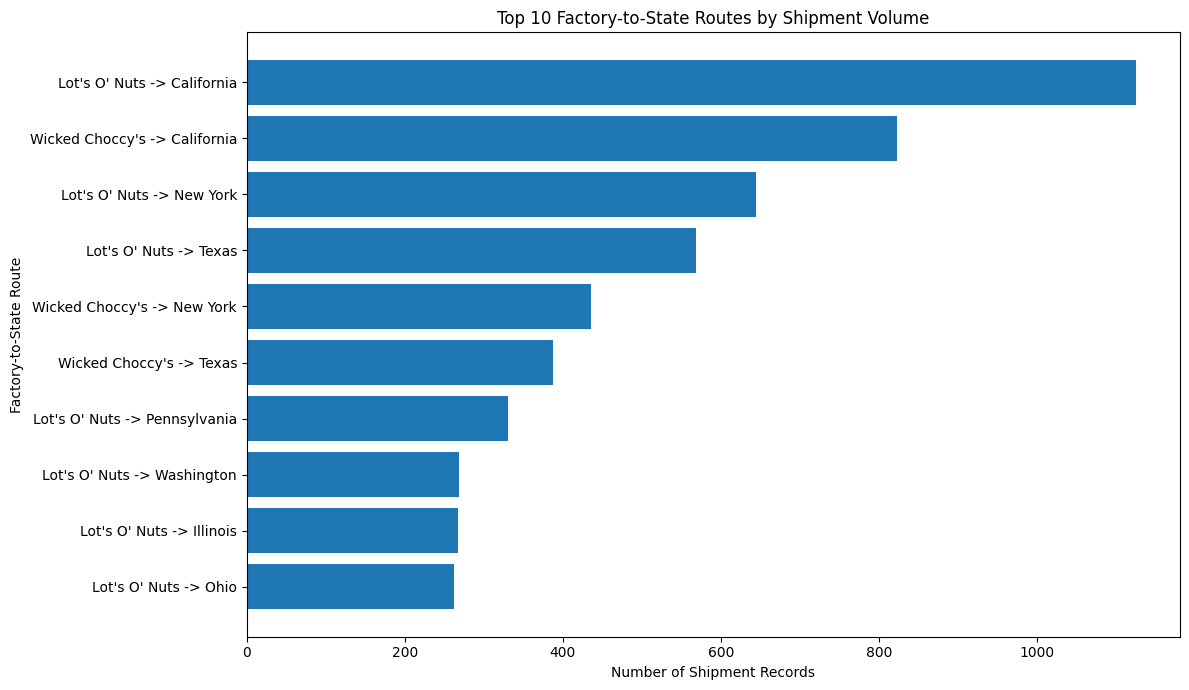

In [38]:
import matplotlib.pyplot as plt

# Select the top 10 routes
top_10_routes = route_summary.nlargest(
    10, "Shipment_Rows"
).sort_values("Shipment_Rows")

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_routes["Factory-to-State Route"],
    top_10_routes["Shipment_Rows"]
)

plt.xlabel("Number of Shipment Records")
plt.ylabel("Factory-to-State Route")
plt.title("Top 10 Factory-to-State Routes by Shipment Volume")

plt.tight_layout()
plt.show()

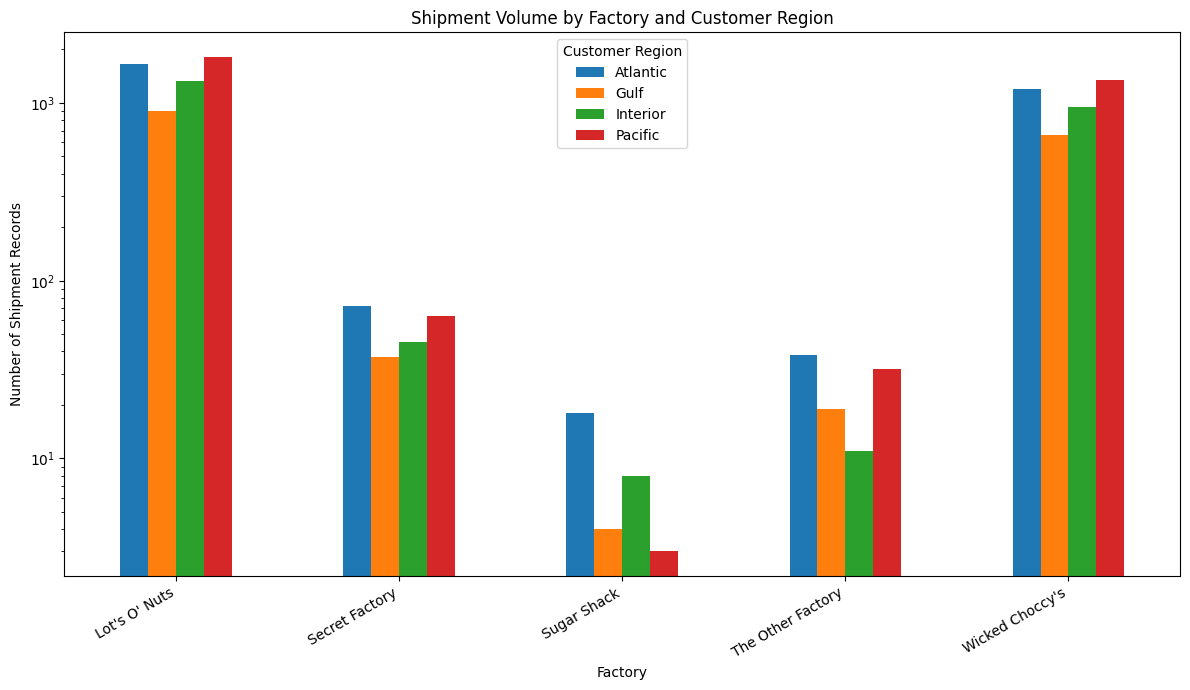

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

region_pivot = region_summary.pivot(
    index="Factory",
    columns="Region",
    values="Shipment_Rows"
).fillna(0)

region_pivot.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Shipment Volume by Factory and Customer Region")
plt.xlabel("Factory")
plt.ylabel("Number of Shipment Records")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Customer Region")
plt.yscale("log")
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

# Summarize shipments by customer region
geographic_summary = (
    df_clean
    .groupby("Region", dropna=False)
    .agg(
        Shipment_Rows=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Lead_Time=("Lead Time (Days)", "mean"),
        Median_Lead_Time=("Lead Time (Days)", "median"),
        Lead_Time_Std=("Lead Time (Days)", "std")
    )
    .reset_index()
)

geographic_summary = geographic_summary.round(2)

geographic_summary = geographic_summary.sort_values(
    "Shipment_Rows",
    ascending=False
)

display(geographic_summary)


,Region,Shipment_Rows,Unique_Orders,Total_Units,Total_Sales,Average_Lead_Time,Median_Lead_Time,Lead_Time_Std
3,Pacific,3253,2744,12466,46301.53,1322.19,1274.0,266.47
0,Atlantic,2986,2476,11159,41197.24,1322.75,1274.0,256.54
2,Interior,2335,1979,8820,32037.60,1323.09,1274.0,262.69
1,Gulf,1620,1350,6209,22247.26,1311.37,1274.0,264.73


In [41]:
state_summary = (
    df_clean
    .groupby(
        ["State/Province", "Country/Region"],
        dropna=False
    )
    .agg(
        Shipment_Rows=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Lead_Time=("Lead Time (Days)", "mean"),
        Lead_Time_Std=("Lead Time (Days)", "std")
    )
    .reset_index()
)

state_summary = state_summary.round(2)

top_15_states = state_summary.nlargest(
    15, "Shipment_Rows"
)

display(top_15_states)

,State/Province,Country/Region,Shipment_Rows,Unique_Orders,Total_Units,Total_Sales,Average_Lead_Time,Lead_Time_Std
5,California,United States,2001,1686,7667,27917.40,1318.43,264.39
34,New York,United States,1128,942,4224,15541.03,1324.49,249.36
51,Texas,United States,985,833,3724,13416.09,1310.31,266.73
43,Pennsylvania,United States,587,487,2153,8027.03,1324.20,261.76
55,Washington,United States,506,432,1883,6921.15,1360.66,272.12
13,Illinois,United States,492,433,1845,6898.96,1323.15,269.72
39,Ohio,United States,469,392,1759,6768.95,1325.73,263.98
10,Florida,United States,383,319,1379,4804.02,1311.40,269.81
23,Michigan,United States,255,209,946,3331.00,1300.56,244.05
36,North Carolina,United States,249,216,983,3450.86,1334.88,254.99


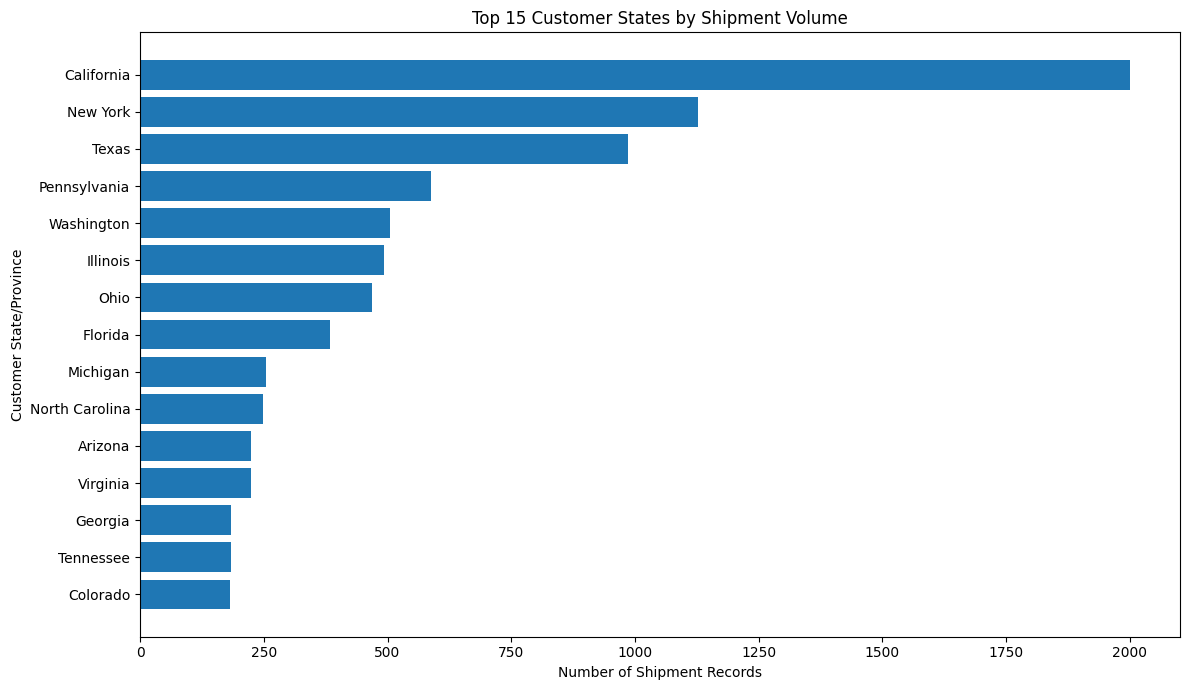

In [42]:
import matplotlib.pyplot as plt

plot_data = top_15_states.sort_values("Shipment_Rows")

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["State/Province"],
    plot_data["Shipment_Rows"]
)

plt.xlabel("Number of Shipment Records")
plt.ylabel("Customer State/Province")
plt.title("Top 15 Customer States by Shipment Volume")

plt.tight_layout()
plt.show()

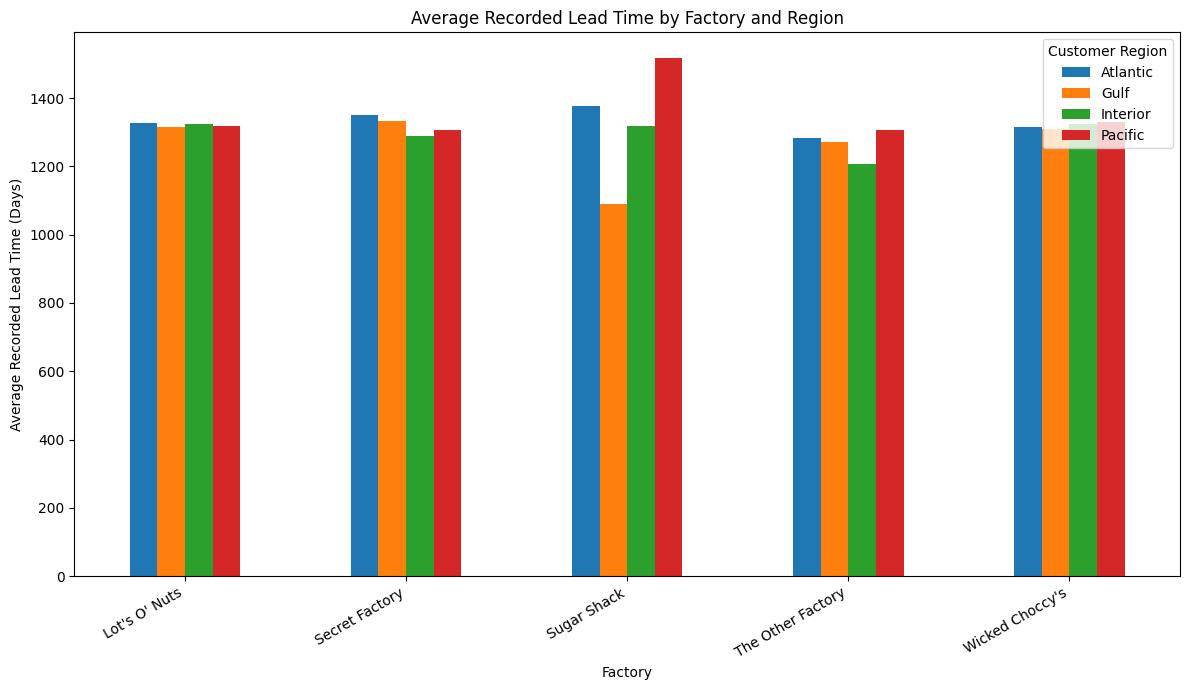

In [43]:
region_lead_time = region_summary.pivot(
    index="Factory",
    columns="Region",
    values="Average_Lead_Time"
)

region_lead_time.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Average Recorded Lead Time by Factory and Region")
plt.xlabel("Factory")
plt.ylabel("Average Recorded Lead Time (Days)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Customer Region")
plt.tight_layout()
plt.show()

In [44]:
factory_locations = pd.DataFrame({
    "Factory": [
        "Lot's O' Nuts",
        "Wicked Choccy's",
        "Sugar Shack",
        "Secret Factory",
        "The Other Factory"
    ],
    "Factory_Latitude": [
        32.881893,
        32.076176,
        48.119140,
        41.446333,
        35.117500
    ],
    "Factory_Longitude": [
        -111.768036,
        -81.088371,
        -96.181150,
        -90.565487,
        -89.971107
    ]
})

display(factory_locations)

,Factory,Factory_Latitude,Factory_Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107


In [45]:
print("Number of customer states:",
      df_clean["State/Province"].nunique())

print("\nNumber of countries:")
print(df_clean["Country/Region"].value_counts())

print("\nMissing customer states:",
      df_clean["State/Province"].isna().sum())

Number of customer states: 59

Number of countries:
Country/Region
United States    9994
Canada            200
Name: count, dtype: Int64

Missing customer states: 0


In [46]:
import pandas as pd

# Aggregate shipment records by destination
destination_summary = (
    df_clean
    .groupby(
        ["Country/Region", "State/Province"],
        dropna=False
    )
    .agg(
        Shipment_Rows=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Average_Lead_Time=("Lead Time (Days)", "mean")
    )
    .reset_index()
)

destination_summary["Average_Lead_Time"] = (
    destination_summary["Average_Lead_Time"].round(2)
)

destination_summary = destination_summary.sort_values(
    "Shipment_Rows",
    ascending=False
)

print("Number of destination locations:",
      len(destination_summary))

display(destination_summary.head(15))

Number of destination locations: 59


,Country/Region,State/Province,Shipment_Rows,Unique_Orders,Total_Sales,Average_Lead_Time
13,United States,California,2001,1686,27917.40,1318.43
40,United States,New York,1128,942,15541.03,1324.49
51,United States,Texas,985,833,13416.09,1310.31
46,United States,Pennsylvania,587,487,8027.03,1324.20
55,United States,Washington,506,432,6921.15,1360.66
21,United States,Illinois,492,433,6898.96,1323.15
43,United States,Ohio,469,392,6768.95,1325.73
18,United States,Florida,383,319,4804.02,1311.40
30,United States,Michigan,255,209,3331.00,1300.56
41,United States,North Carolina,249,216,3450.86,1334.88


In [47]:
us_destination_summary = destination_summary[
    destination_summary["Country/Region"] == "United States"
].copy()

print("Number of US destination states/provinces:",
      us_destination_summary["State/Province"].nunique())

display(us_destination_summary.head(10))

Number of US destination states/provinces: 49


,Country/Region,State/Province,Shipment_Rows,Unique_Orders,Total_Sales,Average_Lead_Time
13,United States,California,2001,1686,27917.40,1318.43
40,United States,New York,1128,942,15541.03,1324.49
51,United States,Texas,985,833,13416.09,1310.31
46,United States,Pennsylvania,587,487,8027.03,1324.20
55,United States,Washington,506,432,6921.15,1360.66
21,United States,Illinois,492,433,6898.96,1323.15
43,United States,Ohio,469,392,6768.95,1325.73
18,United States,Florida,383,319,4804.02,1311.40
30,United States,Michigan,255,209,3331.00,1300.56
41,United States,North Carolina,249,216,3450.86,1334.88


In [48]:
!pip -q install plotly

In [49]:
import plotly.express as px
import pandas as pd

In [50]:
state_abbreviations = {
    "Alabama": "AL", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT",
    "Delaware": "DE", "Florida": "FL", "Georgia": "GA",
    "Idaho": "ID", "Illinois": "IL", "Indiana": "IN",
    "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY",
    "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
    "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
    "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH",
    "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH",
    "Oklahoma": "OK", "Oregon": "OR", "Pennsylvania": "PA",
    "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
    "Alaska": "AK", "Hawaii": "HI"
}

us_map_data = us_destination_summary.copy()

us_map_data["State_Code"] = (
    us_map_data["State/Province"].map(state_abbreviations)
)

print("States successfully mapped:",
      us_map_data["State_Code"].notna().sum())

print("\nUnmapped states:")
display(
    us_map_data.loc[
        us_map_data["State_Code"].isna(),
        ["State/Province", "Shipment_Rows"]
    ]
)

States successfully mapped: 48

Unmapped states:


,State/Province,Shipment_Rows
17,District Of Columbia,10


In [51]:
us_map_valid = us_map_data.dropna(
    subset=["State_Code"]
).copy()

fig = px.choropleth(
    us_map_valid,
    locations="State_Code",
    locationmode="USA-states",
    color="Shipment_Rows",
    hover_name="State/Province",
    hover_data={
        "Shipment_Rows": True,
        "Unique_Orders": True,
        "Total_Sales": ":,.2f",
        "State_Code": False
    },
    scope="usa",
    color_continuous_scale="Blues",
    title="US Shipment Volume by Customer State"
)

fig.update_layout(
    width=1000,
    height=650
)

fig.show()

In [52]:
# Focus on states with at least 100 shipment records
bottleneck_candidates = state_summary[
    (state_summary["Country/Region"] == "United States") &
    (state_summary["Shipment_Rows"] >= 100)
].copy()

# Rank by shipment volume and recorded lead time
bottleneck_candidates = bottleneck_candidates.sort_values(
    ["Shipment_Rows", "Average_Lead_Time"],
    ascending=[False, False]
)

display(
    bottleneck_candidates[
        [
            "State/Province",
            "Shipment_Rows",
            "Unique_Orders",
            "Total_Sales",
            "Average_Lead_Time",
            "Lead_Time_Std"
        ]
    ]
)

,State/Province,Shipment_Rows,Unique_Orders,Total_Sales,Average_Lead_Time,Lead_Time_Std
5,California,2001,1686,27917.40,1318.43,264.39
34,New York,1128,942,15541.03,1324.49,249.36
51,Texas,985,833,13416.09,1310.31,266.73
43,Pennsylvania,587,487,8027.03,1324.20,261.76
55,Washington,506,432,6921.15,1360.66,272.12
13,Illinois,492,433,6898.96,1323.15,269.72
39,Ohio,469,392,6768.95,1325.73,263.98
10,Florida,383,319,4804.02,1311.40,269.81
23,Michigan,255,209,3331.00,1300.56,244.05
36,North Carolina,249,216,3450.86,1334.88,254.99


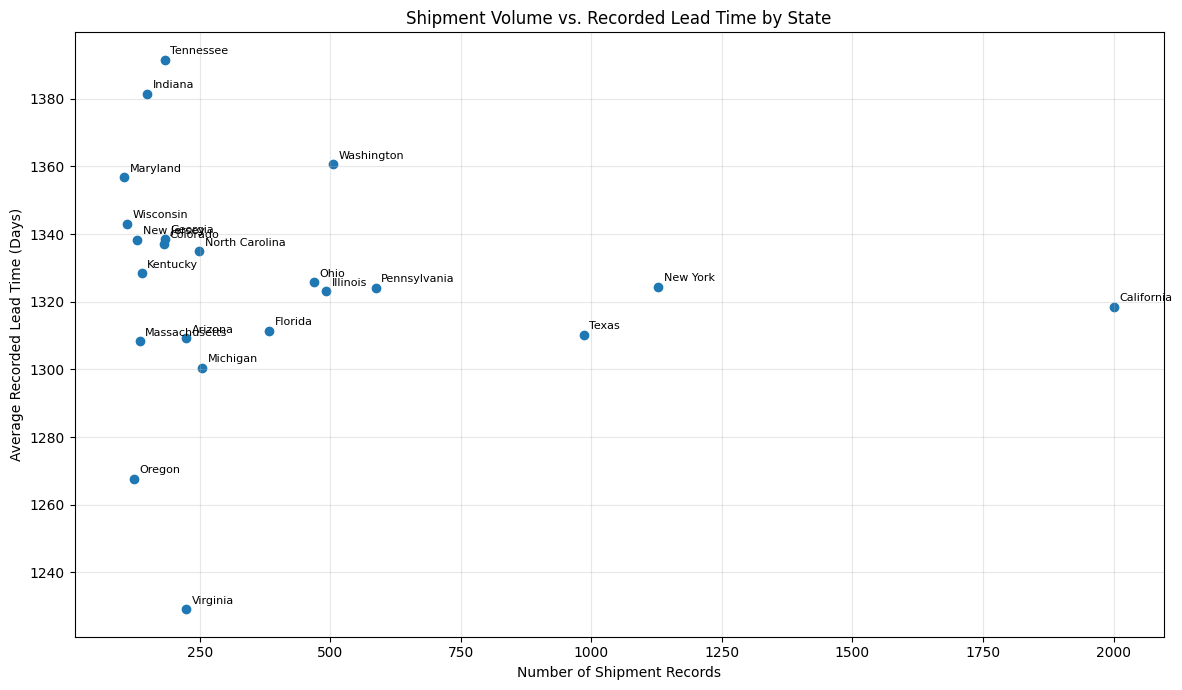

In [53]:
import matplotlib.pyplot as plt

plot_data = bottleneck_candidates.copy()

plt.figure(figsize=(12, 7))

plt.scatter(
    plot_data["Shipment_Rows"],
    plot_data["Average_Lead_Time"]
)

# Label each state
for _, row in plot_data.iterrows():
    plt.annotate(
        row["State/Province"],
        (
            row["Shipment_Rows"],
            row["Average_Lead_Time"]
        ),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Number of Shipment Records")
plt.ylabel("Average Recorded Lead Time (Days)")
plt.title("Shipment Volume vs. Recorded Lead Time by State")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
dashboard_data = df_clean[
    [
        "Row ID",
        "Order ID",
        "Order Date",
        "Ship Date",
        "Ship Mode",
        "Customer ID",
        "Country/Region",
        "State/Province",
        "Region",
        "Product Name",
        "Division",
        "Factory",
        "Units",
        "Sales",
        "Gross Profit",
        "Cost",
        "Lead Time (Days)",
        "Factory-to-State Route",
        "Factory-to-Region Route"
    ]
].copy()

print("Dashboard dataset shape:", dashboard_data.shape)
print("\nMissing values in selected columns:")
display(
    dashboard_data.isna().sum().to_frame("Missing Values")
)

display(dashboard_data.head())

Dashboard dataset shape: (10194, 19)

Missing values in selected columns:


,Missing Values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
State/Province,0
Region,0
Product Name,0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,State/Province,Region,Product Name,Division,Factory,Units,Sales,Gross Profit,Cost,Lead Time (Days),Factory-to-State Route,Factory-to-Region Route
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Texas,Interior,Wonka Bar - Milk Chocolate,Chocolate,Wicked Choccy's,2,6.50,4.22,2.28,909,Wicked Choccy's -> Texas,Wicked Choccy's -> Interior
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Illinois,Interior,Wonka Bar - Triple Dazzle Caramel,Chocolate,Wicked Choccy's,2,7.50,4.90,2.60,909,Wicked Choccy's -> Illinois,Wicked Choccy's -> Interior
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Illinois,Interior,Wonka Bar - Nutty Crunch Surprise,Chocolate,Lot's O' Nuts,3,10.47,7.47,3.00,909,Lot's O' Nuts -> Illinois,Lot's O' Nuts -> Interior
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Illinois,Interior,Wonka Bar -Scrumdiddlyumptious,Chocolate,Lot's O' Nuts,3,10.80,7.50,3.30,909,Lot's O' Nuts -> Illinois,Lot's O' Nuts -> Interior
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Pennsylvania,Atlantic,Wonka Bar - Triple Dazzle Caramel,Chocolate,Wicked Choccy's,3,11.25,7.35,3.90,912,Wicked Choccy's -> Pennsylvania,Wicked Choccy's -> Atlantic


In [55]:
output_file = "nassau_candy_route_analysis.csv"

dashboard_data.to_csv(output_file, index=False)

print("Export completed:", output_file)

Export completed: nassau_candy_route_analysis.csv


In [56]:
from google.colab import files
#files.download("nassau_candy_route_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
# Overall dashboard metrics

total_shipments = len(dashboard_data)
total_orders = dashboard_data["Order ID"].nunique()
total_factories = dashboard_data["Factory"].nunique()
total_states = dashboard_data["State/Province"].nunique()
total_sales = dashboard_data["Sales"].sum()
total_units = dashboard_data["Units"].sum()

average_recorded_lead_time = (
    dashboard_data["Lead Time (Days)"].mean()
)

print("===== NASSAU CANDY ROUTE ANALYSIS =====")
print("Total shipment records:", total_shipments)
print("Unique orders:", total_orders)
print("Factories:", total_factories)
print("Customer destinations:", total_states)
print("Total units:", total_units)
print("Total sales:", round(total_sales, 2))
print(
    "Average recorded lead time (days):",
    round(average_recorded_lead_time, 2)
)

===== NASSAU CANDY ROUTE ANALYSIS =====
Total shipment records: 10194
Unique orders: 8549
Factories: 5
Customer destinations: 59
Total units: 38654
Total sales: 141783.63
Average recorded lead time (days): 1320.84


In [58]:
factory_dashboard = (
    dashboard_data
    .groupby("Factory")
    .agg(
        Shipment_Records=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Recorded_Lead_Time=("Lead Time (Days)", "mean")
    )
    .reset_index()
)

factory_dashboard["Total_Sales"] = (
    factory_dashboard["Total_Sales"].round(2)
)

factory_dashboard["Average_Recorded_Lead_Time"] = (
    factory_dashboard["Average_Recorded_Lead_Time"].round(2)
)

display(
    factory_dashboard.sort_values(
        "Shipment_Records",
        ascending=False
    )
)

,Factory,Shipment_Records,Unique_Orders,Total_Units,Total_Sales,Average_Recorded_Lead_Time
0,Lot's O' Nuts,5692,4760,21412,76340.15,1321.23
4,Wicked Choccy's,4152,3445,15863,55352.75,1321.08
1,Secret Factory,217,213,884,8587.50,1321.87
3,The Other Factory,100,98,388,1282.25,1280.28
2,Sugar Shack,33,33,107,220.98,1340.03


In [59]:
dashboard_data.to_csv(
    "nassau_candy_dashboard_data.csv",
    index=False
)

factory_dashboard.to_csv(
    "nassau_candy_factory_summary.csv",
    index=False
)

print("Both dashboard CSV files have been created.")

Both dashboard CSV files have been created.


In [60]:
from google.colab import files

#files.download("nassau_candy_dashboard_data.csv")
#files.download("nassau_candy_factory_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>